# MobileCLIP2-S0 sobre CINIC-10: fine-tuning supervisado

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rivas-vega/A3_Recv/blob/main/mobileclip_s0_cinic.ipynb)

**Pregunta:** ¿qué rendimiento consigue un encoder visual pequeño ajustado con etiquetas reales y datos externos permitidos?

Un solo experimento, sin PE, sin destilación adicional y sin ensembles. La accuracy final es desconocida: este notebook no promete reproducir el resultado del modelo grande.

**Ejecuta en una sesión Colab con GPU, preferiblemente A100.** Los checkpoints se conservan en Drive. No se modifican las carpetas de experimentos anteriores. El notebook se publica sin datos, pesos, credenciales ni salidas privadas.


## 1. Protocolo fijado antes de la última entrega

| Conjunto | Uso |
|---|---|
| CINIC-10 `train` (90.000 antes de deduplicar) | Entrenamiento supervisado |
| CINIC-10 `valid` | Selección fija de hasta 10.000 ejemplos: 1.000 por clase tras deduplicar |
| Resto de CINIC `valid` y todo CINIC `test` | No se utilizan para entrenar ni seleccionar |
| `validation.npz` de la competición | Auditoría posterior, no selección; su origen no se presupone |
| `test.npz` de la competición | Solo inferencia final, después de congelar el método |

Se eliminan del entrenamiento duplicados exactos RGB (también reflejados horizontalmente) respecto a todo CINIC `valid` y a vuestra validación. Se eliminan duplicados de selección respecto a vuestra validación. No equivale a una búsqueda de casi duplicados ni demuestra ausencia de solapamientos con el preentrenamiento del modelo.

CINIC contiene CIFAR e ImageNet. No se añade además el train de la competición: este es el experimento **CINIC-only**. La validación de la competición ya se ha usado en experimentos previos; no la presentaremos como un holdout nuevo e intacto.

**Selección:** mayor accuracy en validación CINIC; en empate, menor entropía cruzada. Ni las puntuaciones Kaggle previas ni los píxeles/etiquetas del test intervienen en el entrenamiento o la selección. No se usa CIFAR-10-Warehouse. No se envía nada automáticamente a Kaggle.


## 2. Dependencias

OpenCLIP y timm incluyen la arquitectura S0 y la adaptación oficial de sus pesos. Se mantiene el PyTorch/torchvision emparejado de Colab. Si habías importado otras versiones de estas bibliotecas, reinicia el runtime después de instalar. No hace falta un token Hugging Face para este checkpoint público.


In [1]:
%pip -q install "open_clip_torch==3.2.0" "timm==1.0.22" "huggingface_hub==0.36.0" "kagglehub==1.0.3" "pyarrow==21.0.0" matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.22.1 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.0 which is incompatible.
bigframes 2.51.0 requires pyarrow>=23.0.1, but you have pyarrow 21.0.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.0 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.


In [2]:
from pathlib import Path
import hashlib, importlib.util, json, os, random, sys, time
import requests, numpy as np, torch
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
RUN_NAME = 'mobileclip2_s0_cinic_supervised_v1'
RUN_DIR = Path('/content/drive/MyDrive/A3_Recv/runs') / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path('/content/cinic10_cache')  # local SSD: faster than thousands of PNGs on Drive
SESSION_HOURS = 6.5  # training budget only; downloads/setup take additional time

ENGINE_COMMIT = 'd78a1ad6430cd78b28298aba3e9ece50c846a436'
ENGINE_SHA256 = '5b524949368f0f21890d6fcfab864c24ac7da8e4b142cf7078c4b53a700ad7d7'
url = f'https://raw.githubusercontent.com/rivas-vega/A3_Recv/{ENGINE_COMMIT}/mobileclip_s0_cinic.py'
r = requests.get(url, timeout=60); r.raise_for_status()
assert hashlib.sha256(r.content).hexdigest() == ENGINE_SHA256, 'Código remoto distinto al revisado'
engine_path = Path('/content/mobileclip_s0_cinic.py'); engine_path.write_bytes(r.content)
spec = importlib.util.spec_from_file_location('s0_cinic', engine_path)
m = importlib.util.module_from_spec(spec); sys.modules[spec.name] = m; spec.loader.exec_module(m)
CFG = dict(m.DEFAULTS)
m.seed_all(CFG['seed'])
assert torch.cuda.is_available(), 'Colab → Entorno de ejecución → Cambiar tipo → GPU'
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM GB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
print('Resultados:', RUN_DIR)
print(json.dumps(CFG, indent=2))


Mounted at /content/drive
GPU: NVIDIA L4
VRAM GB: 22.0
Resultados: /content/drive/MyDrive/A3_Recv/runs/mobileclip2_s0_cinic_supervised_v1
{
  "seed": 42,
  "batch_size": 128,
  "workers": 2,
  "warmup_epochs": 3,
  "max_epochs": 25,
  "min_finetune_epochs": 5,
  "patience": 5,
  "head_lr": 0.001,
  "finetune_head_lr": 0.0001,
  "encoder_lr": 1e-05,
  "weight_decay": 0.01,
  "label_smoothing": 0.05,
  "selection_per_class": 1000,
  "augment": true,
  "image_size": 256,
  "freeze_bn_stats": true
}


## 3. Kaggle con Secretos de Colab (solo se configura una vez)

1. Abre **Secretos**, el icono de llave en la barra lateral izquierda de Colab.
2. Añade un secreto llamado exactamente **`KAGGLE_API_TOKEN`** y pega su valor completo, obtenido en [Kaggle → Settings → API](https://www.kaggle.com/settings/api).
3. Activa **Acceso al notebook** para ese secreto.

Colab conserva el secreto entre sesiones. El código lo lee automáticamente, no lo imprime, no lo escribe en Drive/GitHub y **no usa login interactivo**. Si cambias el secreto, vuelve a ejecutar esta celda: también actualiza la credencial en caché de KaggleHub.

Si tienes el formato antiguo `kaggle.json`, puedes guardar sus valores en **dos secretos**, `KAGGLE_USERNAME` y `KAGGLE_KEY`, en lugar de `KAGGLE_API_TOKEN`. Una clave legacy aislada no equivale a un token moderno.

Puedes reutilizar una descarga mediante `COMPETITION_DIR`. La descarga del paquete puede incluir el archivo test, pero **no se abre hasta la sección final**. Aquí solo se lee `validation.npz`, sin presuponer su procedencia.


In [3]:
import kagglehub
COMPETITION_DIR = ''  # ruta existente opcional; no escribas tokens aquí
if COMPETITION_DIR:
    DATA_ROOT = Path(COMPETITION_DIR)
else:
    m.configure_kaggle_secrets()  # nunca llama a login() ni pide tokens en la salida
    try:
        DATA_ROOT = Path(kagglehub.competition_download('mva-recvis-2026'))
    except Exception as exc:
        if 'auth' in type(exc).__name__.lower() or '401' in str(exc) or '403' in str(exc):
            raise RuntimeError('Kaggle rechazó el acceso. Revisa el secreto y que esa cuenta haya '
                               'aceptado las reglas de mva-recvis-2026. No se abrirá login interactivo.') from None
        raise
audit_x, audit_y, audit_sha = m.read_validation(DATA_ROOT)
print('Validación de competición:', audit_x.shape, 'Origen: no verificado')


Kaggle credentials set.
Kaggle: credenciales leídas de Secretos; sin entrada interactiva.


100%|██████████| 289M/289M [00:16<00:00, 18.7MB/s]

Extracting files...


Validación de competición: (10000, 32, 32, 3) Origen: no verificado


## 4. Descargar CINIC-10 desde Hugging Face y fijar particiones

Edimburgo devuelve 403 desde esta sesión Colab incluso con su enlace directo. Ahora usamos la copia pública de **[Flower: flwrlabs/cinic10](https://huggingface.co/datasets/flwrlabs/cinic10)**, con revisión inmutable y SHA256 de cada archivo. No se contacta con Edimburgo y no se requiere token Hugging Face.

Se descargan **solo `train` y `validation`**; no el test de CINIC ni el de la competición. Antes de adoptar esta copia se compararon los **180.000 nombres, píxeles RGB y etiquetas** con el archivo original de Edimburgo, validado con su MD5 oficial. El código conserva los nombres, el orden y las clases originales. No cambia la receta de entrenamiento.

Los PNG están dentro de archivos Parquet. Se decodifican a uint8 32×32 y se guarda una caché local. La muestra de selección mantiene la semilla 42; las clases se mapean explícitamente al orden de CIFAR-10. El manifiesto registra revisión, hashes y exclusiones por duplicados.


In [4]:
raw, cinic_info = m.download_cinic(CACHE_DIR)
data, data_identity = m.prepare_data(raw, audit_x, audit_y, CFG, RUN_DIR,
    provenance={'cinic': cinic_info, 'competition_validation_sha256': audit_sha})
del raw, audit_x, audit_y
import gc; gc.collect()
print(json.dumps(data_identity['counts'], indent=2))
for key in ('train_y', 'selection_y'):
    print(key, dict(zip(m.CLASSES, np.bincount(data[key], minlength=10).tolist())))


CINIC train: descarga desde Hugging Face; no requiere token.


data/train-00000-of-00001.parquet:   0%|          | 0.00/256M [00:00<?, ?B/s]

CINIC valid: descarga desde Hugging Face; no requiere token.


data/validation-00000-of-00001.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

{
  "train_before": 90000,
  "train_after": 87804,
  "valid_before": 90000,
  "valid_unique_disjoint": 89194,
  "selection_size": 10000,
  "train_overlap_competition_validation": 0,
  "validation_origin": "unknown; no assumption",
  "dedup": "RGB SHA256 and exact horizontal mirror; not near-duplicate search",
  "train_class_counts": [
    8633,
    8968,
    8962,
    8909,
    8632,
    8922,
    8143,
    8786,
    8930,
    8919
  ]
}
train_y {'airplane': 8633, 'automobile': 8968, 'bird': 8962, 'cat': 8909, 'deer': 8632, 'dog': 8922, 'frog': 8143, 'horse': 8786, 'ship': 8930, 'truck': 8919}
selection_y {'airplane': 1000, 'automobile': 1000, 'bird': 1000, 'cat': 1000, 'deer': 1000, 'dog': 1000, 'frog': 1000, 'horse': 1000, 'ship': 1000, 'truck': 1000}


## 5. Arquitectura y pesos de partida

**RGB 32 × 32 → preprocesado oficial 256 × 256 → FastViT MCI0 → vector de 512 dimensiones → capa lineal de 10 clases.**

MobileCLIP2-S0 utiliza una torre visual híbrida eficiente; no es un ViT puro. La cifra publicada de 11,4 M corresponde a la torre visual. Aquí se cuenta el número real de parámetros de la implementación cargada, que puede diferir antes de fusionar sus ramas para inferencia.

Se descarga una revisión inmutable de la adaptación OpenCLIP de los pesos de Apple y se exige carga estricta. Se elimina la torre textual: no se producen prompts, pseudoetiquetas ni puntuaciones de PE. La cabeza clasificadora comienza aleatoria.

**Sin destilación adicional:** nuestro entrenamiento usa solo etiquetas. El preentrenamiento original de MobileCLIP2 sí incorporó profesores; debe declararse en el informe.

No se fusionan las ramas (`reparameterize`) antes de entrenar. La normalización del checkpoint es media 0 y desviación 1: no se sustituye por estadísticas de CINIC o ImageNet.


In [5]:
model, train_tf, eval_tf, model_identity = m.load_model(RUN_DIR, CFG)
print('Preprocesado oficial:', eval_tf)
print('Aumentos de entrenamiento:', train_tf)
print('Parámetros visuales:', f"{model_identity['visual_parameters']:,}")
print('Parámetros de la cabeza:', f"{model_identity['classifier_parameters']:,}")
assert model_identity['model_config']['vision_cfg']['timm_model_name'] == 'fastvit_mci0'
assert model_identity['model_config']['embed_dim'] == 512


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


open_clip_config.json:   0%|          | 0.00/725 [00:00<?, ?B/s]

open_clip_model.safetensors:   0%|          | 0.00/300M [00:00<?, ?B/s]

Preprocesado oficial: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(256, 256))
    <function _convert_to_rgb at 0x7935187663e0>
    ToTensor()
    Normalize(mean=[0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0])
)
Aumentos de entrenamiento: Compose(
    Compose(
    RandomCrop(size=(32, 32), padding=2)
    RandomHorizontalFlip(p=0.5)
    RandomApply(
    p=0.5
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.85, 1.15), hue=(-0.02, 0.02))
)
)
    Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(256, 256))
    <function _convert_to_rgb at 0x7935187663e0>
    ToTensor()
    Normalize(mean=[0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0])
)
)
Parámetros visuales: 11,406,976
Parámetros de la cabeza: 5,130


## 6. Ver imágenes originales, ampliación y aumentos

Solo mostramos **cuatro imágenes aleatorias de entrenamiento**. A la izquierda están los 32 × 32 originales; en el centro, el preprocesado oficial bilineal a 256 × 256; a la derecha, una vista aleatoria de entrenamiento.

Los aumentos son crop suave con padding reflectante de 2 píxeles, flip horizontal y color jitter moderado. Se aplican a 32 × 32 antes del preprocesado. Son técnicas generales; no se han ajustado con imágenes del test. El escalado no recupera detalles perdidos.


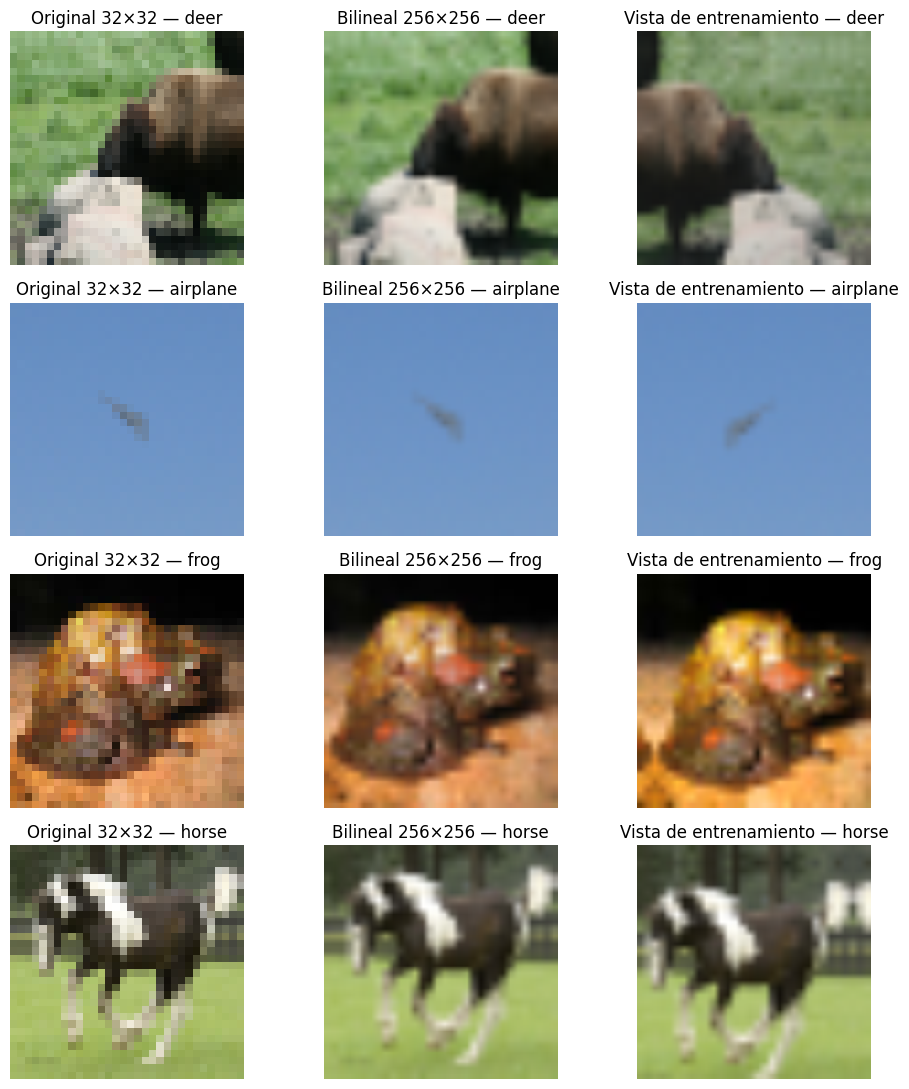

In [6]:
chosen = np.random.default_rng(CFG['seed']).choice(len(data['train_x']), 4, replace=False)
fig, axes = plt.subplots(4, 3, figsize=(10, 11))
mean = torch.tensor(model_identity['preprocess']['mean'])[:, None, None]
std = torch.tensor(model_identity['preprocess']['std'])[:, None, None]
for row, i in enumerate(chosen):
    im = m.Image.fromarray(data['train_x'][i])
    views = [np.asarray(im), (eval_tf(im)*std+mean).permute(1,2,0).clamp(0,1).numpy(),
             (train_tf(im)*std+mean).permute(1,2,0).clamp(0,1).numpy()]
    for col, (view, title) in enumerate(zip(views, ['Original 32×32', 'Bilineal 256×256', 'Vista de entrenamiento'])):
        axes[row,col].imshow(view, interpolation='nearest'); axes[row,col].axis('off')
        axes[row,col].set_title(f'{title} — {m.CLASSES[int(data["train_y"][i])]}')
plt.tight_layout(); plt.show()


## 7. Receta fija y comprobación antes de entrenar

- **Épocas 1–3:** solo cabeza, AdamW y LR 1e-3; encoder congelado y en modo evaluación.
- **Épocas 4–25:** encoder completo LR inicial 1e-5, cabeza 1e-4; descenso coseno. BatchNorm mantiene las estadísticas preentrenadas, aunque sus parámetros afines pueden aprender.
- Entropía cruzada con label smoothing 0,05, weight decay 0,01 y clipping de gradiente a 1.
- Parada tras 5 épocas de fine-tuning sin mejora, como pronto después de 5 épocas de fine-tuning.
- Mejor checkpoint según accuracy CINIC; desempate por menor pérdida. Puede seleccionarse la fase de cabeza si el ajuste completo empeora.
- BF16 cuando la GPU lo soporta; FP16 con GradScaler en caso contrario. No se hace búsqueda de batch o hiperparámetros con el test.

Se guardan `protocol.json`, versiones y hashes **antes de entrenar**. Cambiar el código o datos impide mezclar checkpoints de ejecuciones distintas. La reanudación funciona al final de cada época: una época interrumpida se repite. La reproducción bit a bit no se garantiza entre GPUs/versiones diferentes.


In [7]:
import importlib.metadata as metadata
VERSIONS = {name: metadata.version(name) for name in
    ['torch', 'torchvision', 'open_clip_torch', 'timm', 'huggingface_hub', 'numpy', 'Pillow']}
PROTOCOL = dict(config=CFG, classes=list(m.CLASSES), engine_sha256=ENGINE_SHA256,
    model=model_identity, data=data_identity, versions=VERSIONS,
    selection='CINIC valid accuracy, tie: cross entropy',
    audit='competition validation, after selection only',
    inference='single image, official preprocessing, no TTA',
    supervision='true class labels only; no additional distillation')
m.lock_json(PROTOCOL, RUN_DIR/'protocol.json')
model = model.to('cuda')
sample = torch.stack([eval_tf(m.Image.fromarray(x)) for x in data['train_x'][:2]]).cuda()
model.eval()
with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16):
    logits = model(sample)
assert logits.shape == (2, 10) and torch.isfinite(logits).all()
del sample, logits
print('Carga y forward correctos; protocolo:', m.json_hash(PROTOCOL))


Carga y forward correctos; protocolo: e30525711785ffb7037e520d1fe16d741bf0c69f55355441e5705031ca2b2da5


## 8. Entrenar o reanudar

Ejecuta la celda. La primera época mide el tiempo real de tu GPU y de la carga de datos. El límite de 6,5 h afecta a esta llamada, no a la descarga, y se comprueba entre épocas; no es una promesa de terminar en una sesión.

Si aparece **Pausa por presupuesto**, vuelve a ejecutar esta celda, o abre otra sesión y ejecuta desde el principio con el mismo `RUN_NAME`. No borres la carpeta ni cambies la receta para reanudar. `best.pt` contiene el seleccionado y `last.pt` conserva optimizador y progreso. No se incluyen esos pesos en el ZIP de código de la entrega.


In [8]:
history = m.fit(model, data, train_tf, eval_tf, CFG, RUN_DIR, PROTOCOL, session_hours=SESSION_HOURS)
if (RUN_DIR/'status.json').exists():
    print((RUN_DIR/'status.json').read_text())


Época 1/25 cabeza:   0%|          | 0/686 [00:00<?, ?it/s]

Validación CINIC: 88.370%; mejor época 1; tiempo acumulado 0.06 h


Época 2/25 cabeza:   0%|          | 0/686 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7935a4e6b240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7935a4e6b240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validación CINIC: 88.850%; mejor época 2; tiempo acumulado 0.11 h


Época 3/25 cabeza:   0%|          | 0/686 [00:00<?, ?it/s]

... (41 outputs left out)

Época 24/25 fine-tuning:   0%|          | 0/686 [00:00<?, ?it/s]

Validación CINIC: 94.650%; mejor época 23; tiempo acumulado 3.46 h


Época 25/25 fine-tuning:   0%|          | 0/686 [00:00<?, ?it/s]

Validación CINIC: 94.780%; mejor época 25; tiempo acumulado 3.61 h
{
  "best": {
    "accuracy": 0.9478,
    "epoch": 25,
    "loss": 0.21887738995552064
  },
  "completed": true,
  "stop_reason": "max_epochs",
  "training_hours": 3.6130425947980567
}


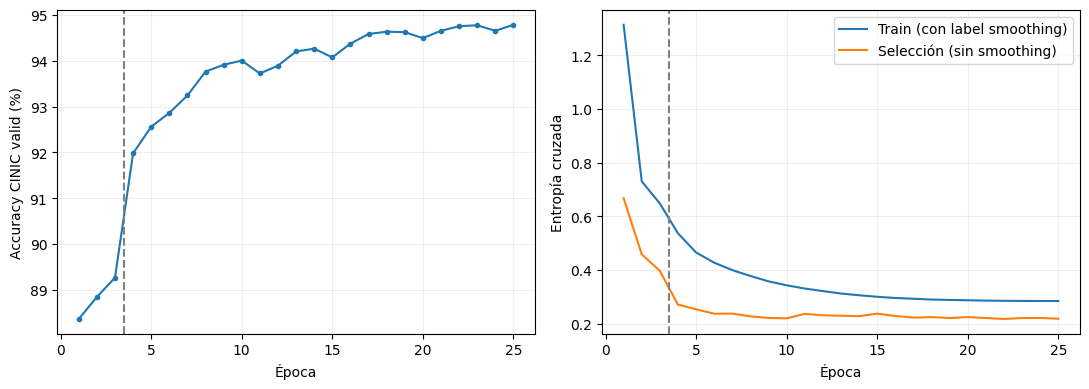

In [9]:
history = json.loads((RUN_DIR/'history.json').read_text())
fig, axes = plt.subplots(1,2,figsize=(11,4))
epochs = [r['epoch'] for r in history]
axes[0].plot(epochs,[100*r['selection_accuracy'] for r in history],marker='.')
axes[0].set_ylabel('Accuracy CINIC valid (%)')
axes[1].plot(epochs,[r['train_loss'] for r in history],label='Train (con label smoothing)')
axes[1].plot(epochs,[r['selection_loss'] for r in history],label='Selección (sin smoothing)')
axes[1].legend(); axes[1].set_ylabel('Entropía cruzada')
for ax in axes:
    ax.axvline(CFG['warmup_epochs']+.5,color='gray',ls='--'); ax.set_xlabel('Época'); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


## 9. Auditoría posterior: cargar el checkpoint ya elegido

Solo se ejecuta cuando el entrenamiento ha terminado por parada temprana o máximo de épocas. Esta evaluación de vuestra validación no cambia la selección ni provoca otro entrenamiento. No equivale a una estimación garantizada de Kaggle.

La matriz y los errores son de **validación etiquetada**, nunca del test oculto. No se deben usar estos resultados para escoger otra receta dentro de este experimento final.


{
  "selected_checkpoint": {
    "accuracy": 0.9478,
    "loss": 0.21887738995552064,
    "epoch": 25
  },
  "competition_validation": {
    "accuracy": 0.9799,
    "loss": 0.11141214523315429
  },
  "status": {
    "best": {
      "accuracy": 0.9478,
      "epoch": 25,
      "loss": 0.21887738995552064
    },
    "completed": true,
    "stop_reason": "max_epochs",
    "training_hours": 3.6130425947980567
  },
  "total_parameters": 11412106,
  "checkpoint_megabytes": 43.97811412811279,
  "gpu": "NVIDIA L4",
  "max_allocated_vram_gb": 10.710631370544434,
  "note": "No Kaggle score computed; audit did not select the model"
}


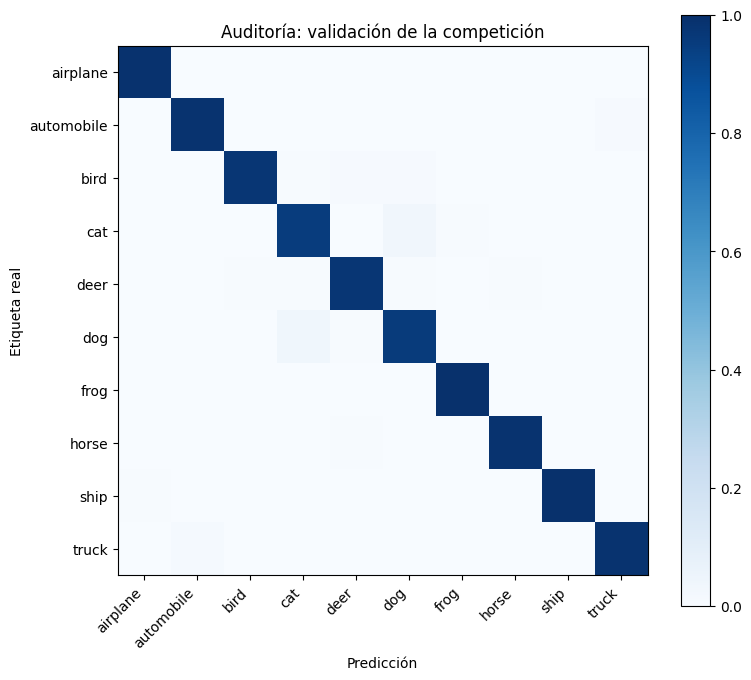

In [10]:
best = m.load_selected(model, RUN_DIR, PROTOCOL)
device = next(model.parameters()).device
amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
audit_dl = m.loader(data['audit_x'], data['audit_y'], eval_tf, CFG)
audit_metrics, audit_probs = m.evaluate(model, audit_dl, device, amp_dtype)
report = dict(selected_checkpoint=best, competition_validation=audit_metrics,
    status=json.loads((RUN_DIR/'status.json').read_text()),
    total_parameters=sum(p.numel() for p in model.parameters()),
    checkpoint_megabytes=(RUN_DIR/'best.pt').stat().st_size/2**20,
    gpu=torch.cuda.get_device_name(0), max_allocated_vram_gb=torch.cuda.max_memory_allocated()/2**30,
    note='No Kaggle score computed; audit did not select the model')
m.atomic_json(report, RUN_DIR/'audit_report.json')
print(json.dumps(report, indent=2))
truth=data['audit_y']; pred=audit_probs.argmax(1)
conf=np.zeros((10,10),dtype=np.int64); np.add.at(conf,(truth,pred),1)
normalized=conf/np.maximum(conf.sum(1,keepdims=True),1)
fig,ax=plt.subplots(figsize=(8,7)); im=ax.imshow(normalized,vmin=0,vmax=1,cmap='Blues')
ax.set_xticks(range(10),m.CLASSES,rotation=45,ha='right');ax.set_yticks(range(10),m.CLASSES)
ax.set_xlabel('Predicción');ax.set_ylabel('Etiqueta real');ax.set_title('Auditoría: validación de la competición')
fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()


## 10. Única exportación final

El notebook **no abre el test por defecto**, ni siquiera con “Ejecutar todo”. Cuando el entrenamiento esté completo, cambia `EXPORT_FINAL` a `True` y ejecuta esta celda para generar el único CSV. Esto solo exporta: **no consume una entrega Kaggle**.

Se congela el hash del checkpoint antes de leer el test. Se leen exclusivamente `images` e `ids`, se alinea con `sample_submission.csv` y se guarda un registro de integridad. No hay score local del test, ajuste de prompts, TTA, selección de ensemble ni entrenamiento posterior.

La elección de entregar este experimento debe respetar el protocolo fijado, no basarse en nuevas comparaciones con el leaderboard.


In [12]:
EXPORT_FINAL = True
if EXPORT_FINAL:
    csv_path = m.export_final(model, DATA_ROOT, eval_tf, CFG, RUN_DIR, PROTOCOL)
    print('Único CSV final:', csv_path)
    from google.colab import files
    files.download(str(csv_path))
else:
    print('Exportación desactivada. El test no se ha leído.')


Único CSV final: /content/drive/MyDrive/A3_Recv/runs/mobileclip2_s0_cinic_supervised_v1/submission_mobileclip2_s0_cinic.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Qué documentar en el informe

La contribución de este experimento es adaptar un encoder pequeño con etiquetas de CINIC-10. **Un solo entrenamiento no demuestra causalmente que CINIC o los aumentos mejoren la accuracy**: para afirmarlo harían falta ablaciones con selección exclusivamente interna.

Reporta número real de parámetros, tamaño de entrenamiento tras deduplicación, preentrenamiento original, receta, época seleccionada, métricas CINIC y auditoría por separado, tiempo real y resultado de la única entrega si finalmente se realiza. No atribuyas a este modelo el score anterior de PE.

Fuentes:
- [Apple MobileCLIP2-S0 y licencia de los pesos](https://huggingface.co/apple/MobileCLIP2-S0)
- [Adaptación OpenCLIP y revisión utilizada](https://huggingface.co/timm/MobileCLIP2-S0-OpenCLIP/tree/095906d28bf54d7584dc411e8ffe448f34289e05)
- [CINIC-10: documentación y procedencia](https://github.com/BayesWatch/cinic-10)
- [Copia Flower verificada](https://huggingface.co/datasets/flwrlabs/cinic10/tree/44c23bab233087df95aad862c5b6fa0e5e6030cf)
- [Archivo oficial CINIC-10](https://datashare.is.ed.ac.uk/handle/10283/3192)

Comprobaciones de desarrollo: catorce tests sintéticos de separación de datos, selección, gradientes, bloqueo de protocolo y exportación. También se cargó el checkpoint real y se verificó un forward y un paso de aprendizaje en CPU con OpenCLIP 3.2.0 / timm 1.0.22 (11.406.976 parámetros visuales). El entrenamiento completo y su duración en A100 se verifican al ejecutar este notebook; no se presentan resultados inventados.
